### Αναλυση Δεδομενων Αυτοκινητων και Προβλεψη Καταναλωσης Καυσιμου
Στο project αυτο αναλυουμε δεδομενα αυτοκινητων με τη χρηση Python. Εξεταζουμε πως χαρακτηριστικα οπως το βαρος, η ιπποδυναμη και ο κυβισμος σχετιζονται με την καταναλωση καυσιμου.
Στη συνεχεια χρησιμοποιουμε μοντελα παλινδρομησης για να προβλεψουμε την καταναλωση σε L/100km. Τελος, συγκρινουμε τα αποτελεσματα και αξιολογουμε την αποδοση των μοντελων. (project ακομα υπο κατασκευη)

In [1]:
# Εισαγωγη βιβλιοθηκης
import pandas as pd

# Ορισμος στηλων των δεδομενων
columns = [
    'mpg', 'cylinders', 'displacement',
    'horsepower', 'weight', 'acceleration',
    'model_year', 'origin', 'car_name'
]

# Αναγνωση αρχειου απο την python
df = pd.read_csv(
    'auto-mpg.data',
    sep=r'\s+',
    header=None,
    names=columns,
    na_values='?'
)

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 1. Data inseption
Χρήσιμες πληροφορίες για τα δεδομένα μας

In [2]:
print('Διαστάσεις δεδομένων:', df.shape)

print('\nΠληροφορίες δεδομένων:')
df.info()

print('\nΆθροισμα δεδομένων που λείπουν ανά στήλη:')
print(df.isnull().sum())

print('\nΒασικά στατιστικά αποτελέσματα:')
display(df.describe())

Διαστάσεις δεδομένων: (398, 9)

Πληροφορίες δεδομένων:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB

Άθροισμα δεδομένων που λείπουν ανά στήλη:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Βασικά στατιστικά αποτελέσματα:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


## 2. Καθαρισμος δεδομενων
Παρατηρησαμε προηγουμενως οτι λειπουν 6 δεδομενα στη στηλη horsepower οποτε θα τα αντικαταστησουμε με τον μεσο ορο της στηλης αυτης

In [ ]:
df[df['horsepower'].isnull()]


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


In [9]:
#Εισαγουμε numpy
import numpy as np

In [12]:
# Μετατρεπουμε τη στηλη horsepower σε float και υπολογιζουμε στη στηλη αυτη (axis=0) τον μεσο ορο

avg_horsepower = df['horsepower'].astype('float').mean(axis=0)
print('average horsepower: ', avg_horsepower)

# Αντικατασταση Nan με avg_horsepower
df['horsepower'] = df['horsepower'].replace(np.nan, avg_horsepower)
print(df['horsepower'].isnull().sum())

average horsepower:  104.46938775510205
0


### Παρατηρηση
Για να δουλεψουμε καλυτερα με τα δεδομενα θα ηταν ευλογο να μετατρεψουμε το mpg(μιλια ανα γαλονι) σε L/100Km(Λιτρο ανα 100 χιλιομετρα)

In [ ]:
# Μετατροπη απο mpg σε L/100Km
df['mpg'] = 235.215 / df['mpg']

#Αλλαγη ονοματος στηλης mpg
df.rename(columns = {'mpg': 'L/100Km'}, inplace=True)

#Ελεγχος αποτελεσματων
df.head()

,L/100Km,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,13.067500,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.681000,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,13.067500,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,14.700938,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,13.836176,8,302.0,140.0,3449.0,10.5,70,1,ford torino


# 3. Διερευνητική Ανάλυση Δεδομένων
Εξετάζουμε τις σχέσεις μεταξύ των χαρακτηριστικών των οχημάτων και της απόδοσης καυσίμου (MPG).

In [29]:
# Συσχετισεις ολων
df.corr(numeric_only=True)

,L/100Km,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
L/100Km,1.000000,0.839278,0.866631,0.850880,0.885219,-0.455750,-0.557427,-0.530213
cylinders,0.839278,1.000000,0.950721,0.838939,0.896017,-0.505419,-0.348746,-0.562543
displacement,0.866631,0.950721,1.000000,0.893646,0.932824,-0.543684,-0.370164,-0.609409
horsepower,0.850880,0.838939,0.893646,1.000000,0.860574,-0.684259,-0.411651,-0.453669
weight,0.885219,0.896017,0.932824,0.860574,1.000000,-0.417457,-0.306564,-0.581024
acceleration,-0.455750,-0.505419,-0.543684,-0.684259,-0.417457,1.000000,0.288137,0.205873
model_year,-0.557427,-0.348746,-0.370164,-0.411651,-0.306564,0.288137,1.000000,0.180662
origin,-0.530213,-0.562543,-0.609409,-0.453669,-0.581024,0.205873,0.180662,1.000000


In [31]:
# Συσχετισεις μονο με mpg
df.corr(numeric_only=True)['L/100Km']

L/100Km         1.000000
cylinders       0.839278
displacement    0.866631
horsepower      0.850880
weight          0.885219
acceleration   -0.455750
model_year     -0.557427
origin         -0.530213
Name: L/100Km, dtype: float64

### Παρατηρησεις
Βλεπουμε οτι υπαρχει μεγαλη αρνητικη συσχετιση μεταξυ των τιμων mpg(αποδοση καυσιμου), cylinders(αριθμος κυλινδρων κινητηρα), displacement(Κυβικα κινητηρα), horsepower(ιπποδυναμη) και weight(βαρος)

## 4. Οπτικοποιηση δεδομενων

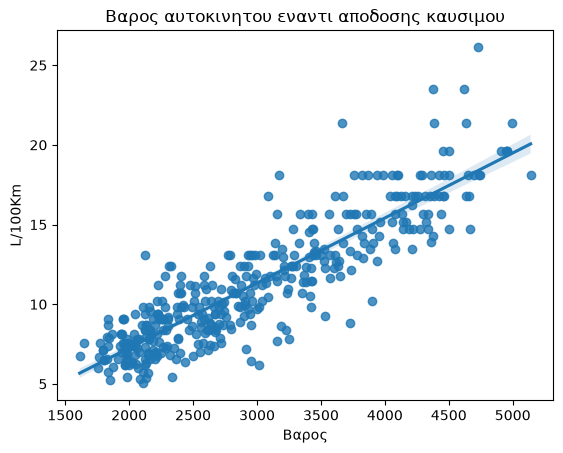

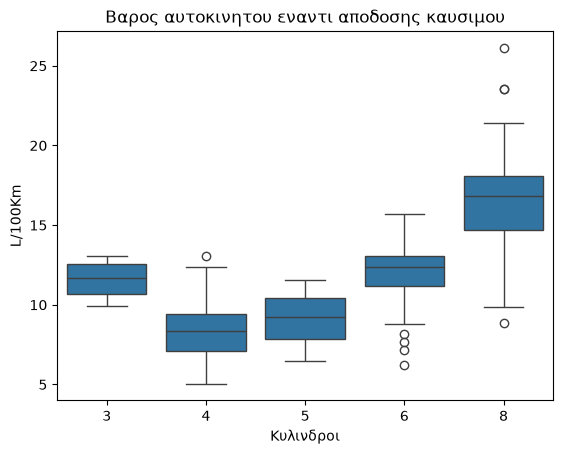

In [36]:
# Εγκατασταση seaborn και matplotlib για γραφηματα
import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(x='weight', y='L/100Km', data=df)

plt.title('Βαρος αυτοκινητου εναντι αποδοσης καυσιμου')
plt.xlabel('Βαρος')
plt.ylabel('L/100Km')
plt.show()

sns.boxplot(x='cylinders', y='L/100Km', data=df)

plt.title('Βαρος αυτοκινητου εναντι αποδοσης καυσιμου')
plt.xlabel('Κυλινδροι')
plt.ylabel('L/100Km')
plt.show()

## Παρατηρησεις

### Σχεση βαρους και καταναλωσης καυσιμου
Παρατηρουμε οτι υπαρχει ισχυρη θετικη συσχετιση μεταξυ βαρους και καταναλωσης καυσιμου. Οσο αυξανεται το βαρος, τοσο αυξανεται και η καταναλωση. Η σχεση φαινεται σχεδον γραμμικη, με καποιες αποκλισεις.
### Σχεση κυλινδρων και καταναλωσης καυσιμου
Απο το Boxplot βλεπουμε οτι τα αυτοκινητα με περισσοτερους κυλινδρους εχουν γενικα μεγαλυτερη καταναλωση. Τα 8κυλινδρα εχουν υψηλοτερη διαμεση τιμη απο τα 4κυλινδρα. Επισης παρουσιαζουν μεγαλυτερη διασπορα στις τιμες τους.

# 3. Επιλογη μοντελου και επομενα βηματα

Με βαση τις συσχετισεις και τα γραφηματα, επιλεγουμε αρχικα το βαρος (weight) για Simple Linear Regression. Σκοπος μας ειναι να προβλεψουμε την καταναλωση καυσιμου (L/100Km).

Στη συνεχεια θα ελεγξουμε την αποδοση του μοντελου με R²(συντελεστη προσδιορισμου) και MSE(μεσο τετραγωνικο σφαλμα) σε test data. Τελος, θα δοκιμασουμε Multiple Linear Regression με περισσοτερες μεταβλητες, για να δουμε αν μπορουμε να πετυχουμε καλυτερες προβλεψεις.

In [ ]:
# %pip install scikit-learn 
# Εισαγουμε την γραμμικη παλινδρομιση
from sklearn.linear_model import LinearRegression

lre = LinearRegression()
print(lre)

LinearRegression()


In [50]:
# Εκπαιδευση μοντελου
lre.fit(df[['weight']], df['L/100Km'])

# Προβλεψη 5 τιμων του μοντελου
Yhat=lre.predict(df[['weight']])
print('Προβλεψεις:', Yhat[0:5])

print('Συντελεστης παλινδρομησης:', lre.coef_)
print('Σταθερος ορος:', lre.intercept_)

Προβλεψεις: [13.38948786 14.16040405 13.11212119 13.09988442 13.16514717]
Συντελεστης παλινδρομησης: [0.00407892]
Σταθερος ορος: -0.9030536518793575


Επομενα βηματα για την ολοκληρωση του project:

1. Διαχωρισμος δεδομενων σε Training και Test Sets.

2. Αξιολογηση Simple Linear Regression με R² και MSE.

3. Εφαρμογη Multiple Linear Regression με περισσοτερες μεταβλητες.

4. Εφαρμογη Polynomial και Ridge Regression.

5. Συγκριση της αποδοσης των μοντελων.

6. Εξαγωγη τελικων συμπερασματων.

Το project θα ενημερωνεται σταδιακα στο GitHub με την προσθηκη νεου κωδικα, αναλυσεων και αποτελεσματων.